# Bayésien Naïf (SPAM Filter)

La base de données « emails » est composée des mails Spam et Non-spam (Ham). En 
utilisant les modules « OS » de Python, on charge la base de données.  

In [1]:
import sys
print(sys.executable)   # shows which Python the kernel uses

c:\Users\ferda\AppData\Local\Python\pythoncore-3.12-64\python.exe


In [2]:
%pip install nltk python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import os, string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from dotenv import load_dotenv
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ferda\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [3]:
# Cell A: imports only
import os, string
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import nltk
from dotenv import load_dotenv
print("imports OK")

imports OK


In [4]:
# Cell B: the download
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ferda\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [5]:
# Cell C: the data
load_dotenv()
DATA_DIR = os.getenv("DATA_DIR")
print(DATA_DIR)
df = pd.read_csv(os.path.join(DATA_DIR, "spam.csv"), encoding='latin-1')[['v1', 'v2']]
df.columns = ['label', 'message']
print(df['label'].value_counts())

D:/Supervised Learning ML/DB/DB
label
ham     4825
spam     747
Name: count, dtype: int64


In [ ]:
STOP = set(stopwords.words('english'))   # computed once
stemmer = PorterStemmer()

def process(text):
    text = text.lower()
    # remove punctuation 
    text = ''.join(c for c in text if c not in string.punctuation)
    # remove stopwords 
    tokens = [t for t in text.split() if t not in STOP]
    return [stemmer.stem(t) for t in tokens]

print(process("It's holiday and we are playing cricket. Jeff is playing very well!!!"))

['holiday', 'play', 'cricket', 'jeff', 'play', 'well']


In [15]:
print(df['message'][:10].apply(process))

0    [go, jurong, point, crazi, avail, bugi, n, gre...
1                         [ok, lar, joke, wif, u, oni]
2    [free, entri, 2, wkli, comp, win, fa, cup, fin...
3        [u, dun, say, earli, hor, u, c, alreadi, say]
4    [nah, dont, think, goe, usf, live, around, tho...
5    [freemsg, hey, darl, 3, week, word, back, id, ...
6    [even, brother, like, speak, treat, like, aid,...
7    [per, request, mell, mell, oru, minnaminungint...
8    [winner, valu, network, custom, select, receiv...
9    [mobil, 11, month, u, r, entitl, updat, latest...
Name: message, dtype: object


### Vectorisation TF-IDF (sac de mots)

Un modèle ne peut pas lire du texte brut : chaque message est donc transformé en **vecteur numérique** de taille V (nombre de termes distincts du corpus).

Pour un terme $t$ dans un message $d$ :

$$\text{tfidf}(t,d) = \text{tf}(t,d) \times \text{idf}(t), \qquad \text{idf}(t) = \ln\frac{1+n}{1+\text{df}(t)} + 1$$

- $\text{tf}(t,d)$ : nombre d'occurrences de $t$ dans le message $d$
- $n$ : nombre total de messages ; $\text{df}(t)$ : nombre de messages contenant $t$
- Chaque vecteur est ensuite normalisé (norme L2 = 1).

**Intuition :** un mot fréquent dans un message mais **rare** dans le corpus (ex. *prize*, *claim*) reçoit un poids élevé ; un mot présent partout reçoit un poids faible.

`analyzer=process` : le vectoriseur utilise notre fonction de nettoyage (minuscules, ponctuation, mots vides, stemming) pour découper chaque message en termes.

In [16]:
tfidfv = TfidfVectorizer(analyzer=process)
data = tfidfv.fit_transform(df['message'])
print(data.shape)

mess = df.iloc[2]['message']
print(mess)
j = tfidfv.transform([mess]).toarray()[0]
print('index\tidf\ttfidf\tterm')
for i in np.nonzero(j)[0]:
    print(i, f"{tfidfv.idf_[i]:.4f}", f"{j[i]:.4f}", tfidfv.get_feature_names_out()[i], sep='\t')

(5572, 8097)
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
index	idf	tfidf	term
72	8.5271	0.2330	08452810075over18
413	3.6544	0.0999	2
420	8.2394	0.2252	2005
433	8.2394	0.2252	21st
833	8.0163	0.2191	87121
1180	6.0993	0.1667	appli
2076	7.1408	0.1952	comp
2246	7.4285	0.2030	cup
2748	6.5346	0.3572	entri
2868	8.5271	0.4661	fa
2969	6.0993	0.1667	final
3091	4.2096	0.1151	free
4592	5.8190	0.1590	may
5768	8.5271	0.2330	questionstd
5815	8.5271	0.2330	ratetc
5856	5.8645	0.1603	receiv
6959	4.3027	0.1176	text
7099	8.0163	0.2191	tkt
7276	4.5137	0.1234	txt
7708	5.2950	0.1447	win
7741	6.9176	0.1891	wkli


analyzer=process tells TF-IDF to use your cleaning function to split each message into words, instead of its own default.

### Entraînement : Bayésien Naïf multinomial

Pour classer un message, on compare $P(\text{spam} \mid \text{message})$ et $P(\text{ham} \mid \text{message})$. Par la règle de Bayes, avec l'hypothèse **naïve** d'indépendance des termes sachant la classe :

$$P(c \mid \text{message}) \;\propto\; P(c) \prod_{t \in \text{message}} P(t \mid c)$$

- $P(c)$ : probabilité a priori de la classe (≈ 87 % ham, 13 % spam)
- $P(t \mid c)$ : fréquence du terme $t$ dans les messages de la classe $c$, estimée avec un lissage de Laplace ($\alpha = 1$) pour éviter les probabilités nulles

La classe prédite est celle qui maximise ce produit.

Le **Pipeline** enchaîne TF-IDF puis MultinomialNB : le vocabulaire est appris **uniquement sur le train**, le test reste inédit.
Découpage : 80 % train / 20 % test, `random_state=21`.

In [17]:
spam_filter = Pipeline([
    ('vectorizer', TfidfVectorizer(analyzer=process)),  # messages -> vecteurs TF-IDF
    ('classifier', MultinomialNB())                     # apprentissage bayésien naïf
])

x_train, x_test, y_train, y_test = train_test_split(
    df['message'], df['label'], test_size=0.20, random_state=21)

spam_filter.fit(x_train, y_train)

predictions = spam_filter.predict(x_test)
errors = (y_test != predictions)
print('Total number of test cases:', len(y_test))
print('Number of wrong predictions:', errors.sum())

Total number of test cases: 1115
Number of wrong predictions: 39


### Q2 a) Prédictions erronées

- **39 erreurs** sur 1115 messages de test → accuracy ≈ **96,5 %**.
- Répartition : **39 spams prédits ham** (faux négatifs) et **0 ham prédit spam** (faux positifs).

| | Prédit ham | Prédit spam |
|---|---|---|
| **Vrai ham** | 975 | 0 |
| **Vrai spam** | 39 | 101 |

**Interprétation :** toutes les erreurs sont des **spams non détectés** ; le modèle est très prudent (aucun message légitime bloqué) mais laisse passer 28 % des spams (39/140). Cela s'explique par le déséquilibre des classes (≈ 87 % ham) : l'a priori $P(\text{ham})$ pousse le modèle vers *ham*.

**Observation :** les spams ratés sont surtout des messages de rencontre / contenu adulte, peu représentés dans les spams d'apprentissage (majoritairement *win, prize, cash, claim*). Ils contiennent aussi beaucoup de numéros et codes uniques (`87077`, `POBox…`) qui n'apportent aucune information au modèle.

,message,vrai,prédit
419,Send a logo 2 ur lover - 2 names joined by a heart. Txt LOVE NAME1 NAME2 MOBNO eg LOVE ADAM EVE 07123456789 to 87077 Yahoo! POBox36504W45WQ TxtNO 4 no ads 150p,spam,ham
3139,sexy sexy cum and text me im wet and warm and ready for some porn! u up for some fun? THIS MSG IS FREE RECD MSGS 150P INC VAT 2 CANCEL TEXT STOP,spam,ham
3790,"Twinks, bears, scallies, skins and jocks are calling now. Don't miss the weekend's fun. Call 08712466669 at 10p/min. 2 stop texts call 08712460324(nat rate)",spam,ham
2877,"Hey Boys. Want hot XXX pics sent direct 2 ur phone? Txt PORN to 69855, 24Hrs free and then just 50p per day. To stop text STOPBCM SF WC1N3XX",spam,ham
2377,YES! The only place in town to meet exciting adult singles is now in the UK. Txt CHAT to 86688 now! 150p/Msg.,spam,ham
1499,"SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. Psychic? Reply ANS w/question. End? Reply END JSCO",spam,ham
3417,LIFE has never been this much fun and great until you came in. You made it truly special for me. I won't forget you! enjoy @ one gbp/sms,spam,ham
3358,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,spam,ham
2412,I don't know u and u don't know me. Send CHAT to 86688 now and let's find each other! Only 150p/Msg rcvd. HG/Suite342/2Lands/Row/W1J6HL LDN. 18 years or over.,spam,ham
3862,"Oh my god! I've found your number again! I'm so glad, text me back xafter this msgs cst std ntwk chg å£1.50",spam,ham


vrai  prédit
spam  ham       39
Name: count, dtype: int64


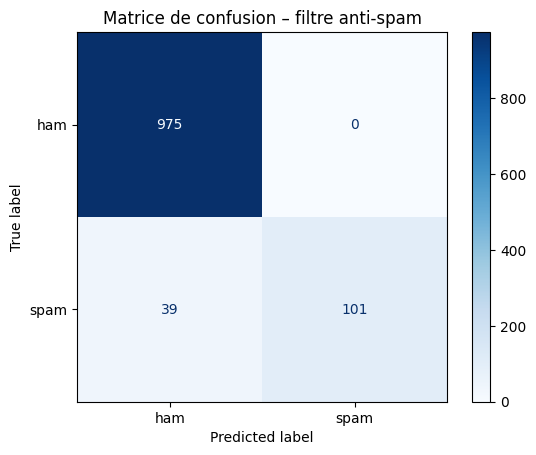

In [18]:
# Messages mal classés
pd.set_option('display.max_colwidth', None)
wrong = pd.DataFrame({'message': x_test[errors],
                      'vrai': y_test[errors],
                      'prédit': predictions[errors]})
display(wrong)
print(wrong[['vrai', 'prédit']].value_counts())

# Matrice de confusion
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=['ham', 'spam'], cmap='Blues')
plt.title('Matrice de confusion – filtre anti-spam')
plt.show()

### Q2 b) Classification d'un nouveau message

Message : *« Your cash-balance is currently 500 pounds - to maximize your cash-in now, send COLLECT to 83600. »*

- Après prétraitement : `cashbal, current, 500, pound, maxim, cashin, send, collect, 83600`
- **Prédiction : spam**, avec $P(\text{spam} \mid \text{message}) \approx 0{,}91$.

**Justification :** les termes *cashbal, cashin, 500, pound, collect, 83600* sont bien plus fréquents dans les spams que dans les hams d'apprentissage ; leur contribution l'emporte largement sur l'a priori $P(\text{ham}) \approx 0{,}86$. Le message présente les marqueurs typiques d'un spam : argent, urgence (*now*), appel à l'action (*send … to*) et numéro court surtaxé.

**Remarque :** ce message est quasi identique à 7 spams du jeu de données (« *Ur cash-balance is currently 500 pounds…* »), dont 6 sont dans le jeu d'apprentissage. La prédiction est donc facile et ne mesure pas vraiment la capacité de généralisation du modèle.

In [19]:
msg = "Your cash-balance is currently 500 pounds - to maximize your cash-in now, send COLLECT to 83600."
print(spam_filter.predict([msg]))
print(spam_filter.predict_proba([msg]), spam_filter.classes_)

['spam']
[[0.09206795 0.90793205]] ['ham' 'spam']


### Q2 c) Hypothèse d'indépendance conditionnelle

Le modèle suppose que, sachant la classe $c$, les termes sont indépendants :
$$P(t_1, \dots, t_n \mid c) = \prod_i P(t_i \mid c)$$

**Pourquoi elle est systématiquement fausse :** dans un SMS ou un e-mail, les mots dépendent les uns des autres :
- **expressions figées** : *free entry*, *call now*, *text STOP* (voir *free* rend *entry* plus probable) ;
- **syntaxe** : l'ordre et la grammaire lient les mots (*send … to 83600*) ;
- **thématique** : un spam financier contient ensemble *cash, pound, 500, claim*.

**Pourquoi le classifieur reste performant (96,5 % d'accuracy) :**
1. **Seul le classement compte** : la décision est $\hat{c} = \arg\max_c P(c)\prod_i P(t_i \mid c)$. Les probabilités estimées peuvent être fausses (sur-confiance, valeurs proches de 0 ou 1), la décision reste correcte tant que la bonne classe obtient le score le plus élevé.
2. **Les dépendances vont dans le même sens** : des mots corrélés (*free, win, prize*) indiquent tous *spam* ; les compter plusieurs fois renforce la bonne décision au lieu de l'inverser.
3. **Peu de paramètres** : seulement $P(c)$ et $P(t \mid c)$, soit ≈ $2V$ paramètres. Modéliser les dépendances entre ~6000 termes serait impossible avec ~4500 messages. Ce biais simplificateur réduit fortement la **variance** (compromis biais–variance).
4. **Vocabulaires très distincts** : les mots de spam (*free, win, claim, txt*) diffèrent nettement de ceux des hams, ce qui rend les classes faciles à séparer même avec un modèle simplifié.

### Q2 d) Discussion des performances

| Classe | Précision | Rappel | F1 |
|---|---|---|---|
| ham | 0,96 | 1,00 | 0,98 |
| **spam** | **1,00** | **0,72** | **0,84** |

Accuracy = 96,5 %.

**Analyse :**
- **Précision spam = 100 %** : aucun message légitime n'est classé spam (0 faux positif).
- **Rappel spam = 72 %** : 39 spams sur 140 passent à travers le filtre (faux négatifs).
- L'accuracy (96,5 %) est trompeuse : un modèle prédisant toujours *ham* obtiendrait déjà ≈ 87 %, à cause du déséquilibre des classes. Le F1 spam (0,84) reflète mieux la qualité réelle du filtre.

**Précision ou rappel ?** D'un point de vue opérationnel, il faut **privilégier la précision** pour la classe spam :
- un **faux positif** (message légitime envoyé dans les spams) est grave : l'utilisateur peut perdre un message important (travail, banque, rendez-vous) sans le savoir ;
- un **faux négatif** (spam dans la boîte de réception) est seulement gênant : l'utilisateur le voit et le supprime.

Notre modèle respecte cette priorité (précision 100 %). Pour l'améliorer, on chercherait à **augmenter le rappel sans dégrader la précision**, par exemple en abaissant le seuil de décision sur `predict_proba`, en rééquilibrant les classes ou en ajoutant des bigrammes.

**Remarque :** l'énoncé appelle `classification_report(predictions, y_test)` ; or scikit-learn attend `(y_true, y_pred)`. Dans cet ordre, précision et rappel sont **inversés**. Nous avons donc utilisé `classification_report(y_test, predictions)`.

- **Macro avg vs weighted avg :** le rappel macro (0,86) traite les deux classes à égalité et révèle la faiblesse sur *spam* ; le weighted avg (0,965), pondéré par le support (975 ham contre 140 spam), est dominé par *ham* et masque ce problème. Avec des classes déséquilibrées, la **moyenne macro** est plus représentative.

In [20]:
# Ordre correct : vraies étiquettes d'abord, puis prédictions
print(classification_report(y_test, predictions, digits=4))

              precision    recall  f1-score   support

         ham     0.9615    1.0000    0.9804       975
        spam     1.0000    0.7214    0.8382       140

    accuracy                         0.9650      1115
   macro avg     0.9808    0.8607    0.9093      1115
weighted avg     0.9664    0.9650    0.9625      1115

